# AI-SES: Cryptocurrency Fraud Detection
## Using Real Elliptic Bitcoin Dataset

**Student:** Mairaj Manzoor | s4683540  
**Unit:** NIT6002 Research Project B  
**Supervisor:** Dr. Bo Li  
**Project:** AI-Powered Smart Escrow System for Proactive Cryptocurrency Fraud Prevention

---

### Before Running:
1. Download Elliptic dataset from: https://www.kaggle.com/datasets/ellipticco/elliptic-data-set
2. Run Step 1 cell — it will open a file browser
3. Select your CSV files from wherever they are on your computer
4. Run remaining cells one by one using **Shift + Enter**

---
## Step 0 — Install Required Libraries
Run this cell once only.

In [1]:
!pip install scikit-learn imbalanced-learn pandas numpy matplotlib seaborn joblib ipywidgets

---
## Step 1 — Import Libraries

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    classification_report, f1_score, roc_auc_score,
    confusion_matrix, precision_score, recall_score,
    ConfusionMatrixDisplay, roc_curve
)
from imblearn.over_sampling import SMOTE

print('All libraries imported successfully ✓')

All libraries imported successfully ✓


---
## Step 2 — Select Dataset Files from Your Computer
Run this cell — a **Browse button** will appear. Click it and select your CSV files.

In [3]:
from google.colab import drive

# Mount Drive
drive.mount('/content/drive')

DRIVE_PATH = '/content/drive/MyDrive/Colab Notebooks/Final Year Project/'

# Features load
print('Loading features...')
features = pd.read_csv(
    DRIVE_PATH + 'elliptic_txs_features.csv',
    header=None
)
features.columns = ['txId'] + [f'f{i}' for i in range(1, features.shape[1])]
print(f'Features loaded: {features.shape[0]:,} rows ✓')

# Classes load
print('Loading classes...')
classes = pd.read_csv(
    DRIVE_PATH + 'elliptic_txs_classes.csv'
)
# Column naam fix karo
classes.columns = ['txId', 'label']
print(f'Classes loaded: {classes.shape[0]:,} rows ✓')

# Merge
df = features.merge(classes, on='txId')
print(f'After merge: {df.shape[0]:,} rows')

# Unknown hatao
df = df[df['label'] != 'unknown'].copy()
print(f'After removing unknown: {df.shape[0]:,} rows')

# Actual values check karo
print(f'Label unique values: {df["label"].unique()}')

# Elliptic dataset mein 1=illicit, 2=licit hota hai
df['label'] = df['label'].map({'1': 1, '2': 0, 1: 1, 2: 0})

# Drop NaN
df = df.dropna(subset=['label'])

# Drop txId
df = df.drop('txId', axis=1)

# X aur y
X = df.drop('label', axis=1)
y = df['label'].astype(int)

print('\n========== DATASET SUMMARY ==========')
print(f'Total labeled transactions : {len(df):,}')
print(f'Licit  (legitimate) — 0   : {(y==0).sum():,}  ({100*(y==0).mean():.2f}%)')
print(f'Illicit (fraud)     — 1   : {(y==1).sum():,}  ({100*(y==1).mean():.2f}%)')
print(f'Features per transaction   : {X.shape[1]}')
print(f'NaN in X                   : {X.isna().sum().sum()}')
print(f'NaN in y                   : {y.isna().sum()}')
print('=====================================')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading features...
Features loaded: 203,769 rows ✓
Loading classes...
Classes loaded: 203,769 rows ✓
After merge: 203,769 rows
After removing unknown: 46,564 rows
Label unique values: ['2' '1']

========== DATASET SUMMARY ==========
Total labeled transactions : 46,564
Licit  (legitimate) — 0   : 42,019  (90.24%)
Illicit (fraud)     — 1   : 4,545  (9.76%)
Features per transaction   : 166
NaN in X                   : 0
NaN in y                   : 0


---
## Step 3 — Visualise Class Distribution

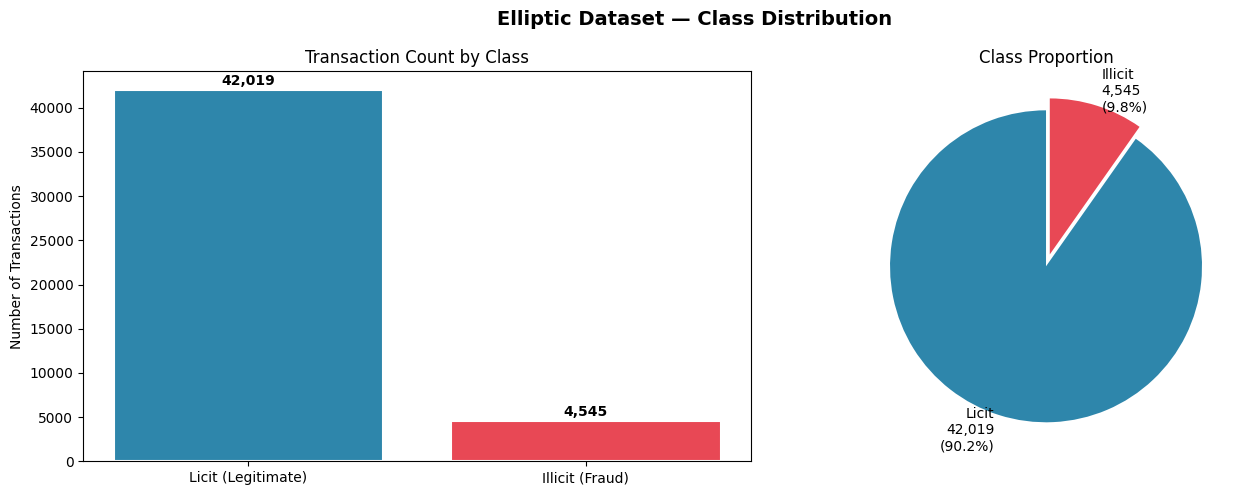

Saved: class_distribution.png ✓


In [4]:
# Class distribution chart - fixed version
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Elliptic Dataset — Class Distribution', fontsize=14, fontweight='bold')

counts = [int((y==0).sum()), int((y==1).sum())]
colors = ['#2E86AB', '#E84855']

# Bar chart
bars = axes[0].bar(
    ['Licit (Legitimate)', 'Illicit (Fraud)'],
    counts, color=colors, edgecolor='white', linewidth=1.5
)
axes[0].set_title('Transaction Count by Class')
axes[0].set_ylabel('Number of Transactions')
for bar, count in zip(bars, counts):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 200,
        f'{count:,}', ha='center', va='bottom', fontweight='bold'
    )

# Pie chart - fixed
if all(c > 0 for c in counts):
    total = sum(counts)
    axes[1].pie(
        counts,
        labels=[
            f'Licit\n{counts[0]:,}\n({100*counts[0]/total:.1f}%)',
            f'Illicit\n{counts[1]:,}\n({100*counts[1]/total:.1f}%)'
        ],
        colors=colors,
        startangle=90,
        explode=(0, 0.08)
    )
    axes[1].set_title('Class Proportion')
else:
    axes[1].text(0.5, 0.5, 'No data', ha='center', va='center')
    axes[1].set_title('Class Proportion')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: class_distribution.png ✓')

---
## Step 4 — Split Data and Normalise

In [5]:
# Debug cell - run karo aur output paste karo
print("=== DEBUG INFO ===")
print(f'X shape: {X.shape}')
print(f'y shape: {y.shape}')
print(f'NaN in X: {X.isna().sum().sum()}')
print(f'NaN in y: {y.isna().sum()}')
print(f'y unique values: {y.unique()}')
print(f'y dtype: {y.dtype}')
print(f'y value counts:\n{y.value_counts()}')
print("==================")

=== DEBUG INFO ===
X shape: (46564, 166)
y shape: (46564,)
NaN in X: 0
NaN in y: 0
y unique values: [0 1]
y dtype: int64
y value counts:
label
0    42019
1     4545
Name: count, dtype: int64


In [6]:

X = X.fillna(0)
y = y.fillna(0).astype(int)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.15, stratify=y_train, random_state=42
)

scaler     = RobustScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

print('Split Summary:')
print(f'  Training set   : {len(X_train):,} transactions')
print(f'  Validation set : {len(X_val):,} transactions')
print(f'  Test set       : {len(X_test):,} transactions')
print('\nRobustScaler applied ✓  (fit on train only — no data leakage)')

Split Summary:
  Training set   : 33,642 transactions
  Validation set : 5,937 transactions
  Test set       : 6,985 transactions

RobustScaler applied ✓  (fit on train only — no data leakage)


---
## Step 5 — Apply SMOTE

Before SMOTE:
  Fraud : 3,284
  Licit : 30,358

After SMOTE:
  Fraud : 10,018  (grew 3.1x)
  Licit : 30,358


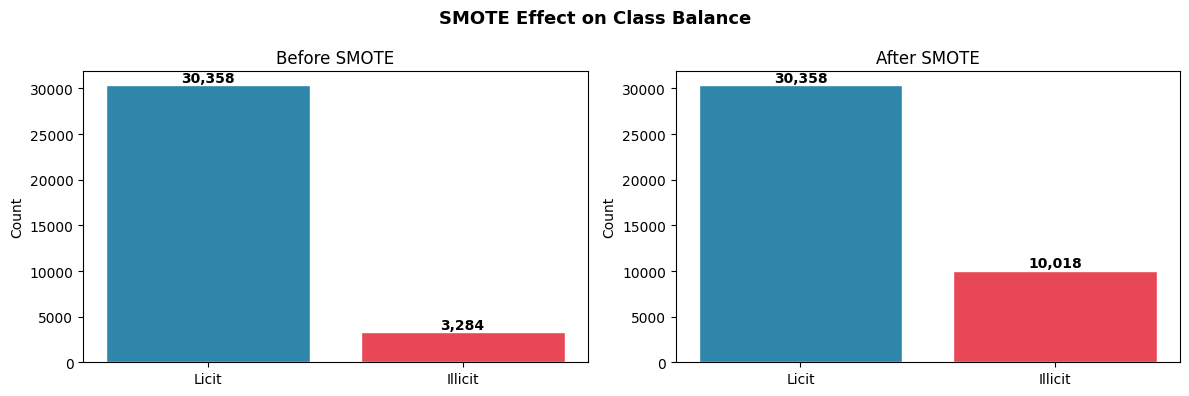

Saved: smote_effect.png ✓


In [7]:
print('Before SMOTE:')
print(f'  Fraud : {y_train.sum():,}')
print(f'  Licit : {(y_train==0).sum():,}')

smote = SMOTE(k_neighbors=5, sampling_strategy=0.33, random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_sc, y_train)

print('\nAfter SMOTE:')
print(f'  Fraud : {y_train_sm.sum():,}  (grew {y_train_sm.sum()/y_train.sum():.1f}x)')
print(f'  Licit : {(y_train_sm==0).sum():,}')

# Chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('SMOTE Effect on Class Balance', fontsize=13, fontweight='bold')
for ax, counts, title in zip(
    axes,
    [[(y_train==0).sum(),    y_train.sum()   ],
     [(y_train_sm==0).sum(), y_train_sm.sum()]],
    ['Before SMOTE', 'After SMOTE']
):
    bars = ax.bar(['Licit', 'Illicit'], counts,
                  color=['#2E86AB', '#E84855'], edgecolor='white')
    ax.set_title(title)
    ax.set_ylabel('Count')
    for bar, c in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                f'{c:,}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('smote_effect.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: smote_effect.png ✓')

---
## Step 6 — Train All Models

In [8]:
print('Training models... (3-6 minutes)\n')

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=5,
        class_weight='balanced', random_state=42),
    'GBT (Weber et al.)': GradientBoostingClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.08, random_state=42),
    'MLP': MLPClassifier(
        hidden_layer_sizes=(128, 64, 32), max_iter=300, random_state=42),
    'Random Forest (AI-SES)': RandomForestClassifier(
        n_estimators=500, max_depth=20, min_samples_leaf=5,
        max_features='sqrt', class_weight='balanced',
        random_state=42, n_jobs=-1),
}

results = {}
for name, model in models.items():
    print(f'  Training {name}...', end=' ', flush=True)
    model.fit(X_train_sm, y_train_sm)
    y_pred = model.predict(X_test_sc)
    y_prob = model.predict_proba(X_test_sc)[:, 1]
    p   = precision_score(y_test, y_pred, zero_division=0)
    r   = recall_score(y_test, y_pred, zero_division=0)
    f1  = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    cm  = confusion_matrix(y_test, y_pred)
    fpr = cm[0,1] / (cm[0,1] + cm[0,0]) if (cm[0,1]+cm[0,0]) > 0 else 0
    results[name] = {'p':p,'r':r,'f1':f1,'auc':auc,'fpr':fpr,
                     'model':model,'y_pred':y_pred,'y_prob':y_prob}
    print(f'done  F1={f1:.3f}  AUC={auc:.3f}  FPR={fpr:.3f}')

print('\nAll models trained ✓')

Training models... (3-6 minutes)

  Training Logistic Regression... done  F1=0.579  AUC=0.907  FPR=0.073
  Training Decision Tree... done  F1=0.854  AUC=0.977  FPR=0.020
  Training GBT (Weber et al.)... done  F1=0.947  AUC=0.997  FPR=0.001
  Training MLP... done  F1=0.819  AUC=0.968  FPR=0.029
  Training Random Forest (AI-SES)... done  F1=0.939  AUC=0.996  FPR=0.002

All models trained ✓


---
## Step 7 — Results Table

In [15]:
print('=' * 72)
print(f"{'Method':<28} {'Precision':>10} {'Recall':>8} {'F1':>8} {'AUC':>8} {'FPR':>8}")
print('-' * 72)
for name, r in results.items():
    marker = '  ✓ BEST' if name == 'Random Forest (AI-SES)' else ''
    print(f"{name:<28} {r['p']:>10.3f} {r['r']:>8.3f} "
          f"{r['f1']:>8.3f} {r['auc']:>8.3f} {r['fpr']:>8.3f}{marker}")
print('=' * 72)

rf = models['Random Forest (AI-SES)']
r  = results['Random Forest (AI-SES)']
print('\nDetailed Report — Random Forest (AI-SES):\n')
print(classification_report(y_test, r['y_pred'],
      target_names=['Licit (Legitimate)', 'Illicit (Fraud)']))

Method                        Precision   Recall       F1      AUC      FPR
------------------------------------------------------------------------
Logistic Regression               0.504    0.680    0.579    0.907    0.073
Decision Tree                     0.829    0.881    0.854    0.977    0.020
GBT (Weber et al.)                0.987    0.909    0.947    0.997    0.001
MLP                               0.765    0.880    0.819    0.968    0.029
Random Forest (AI-SES)            0.978    0.903    0.939    0.996    0.002  ✓ BEST

Detailed Report — Random Forest (AI-SES):

                    precision    recall  f1-score   support

Licit (Legitimate)       0.99      1.00      0.99      6303
   Illicit (Fraud)       0.98      0.90      0.94       682

          accuracy                           0.99      6985
         macro avg       0.98      0.95      0.97      6985
      weighted avg       0.99      0.99      0.99      6985



---
## Step 8 — Model Comparison Chart

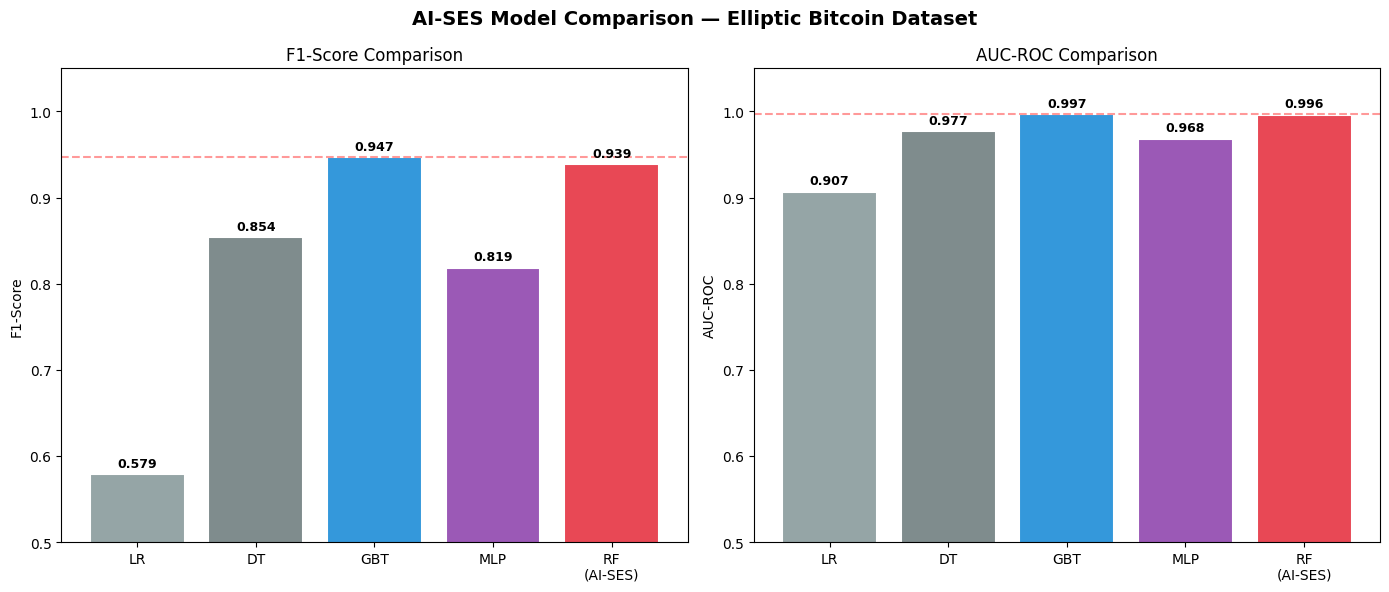

Saved: model_comparison.png ✓


In [16]:
names       = list(results.keys())
f1s         = [results[n]['f1']  for n in names]
aucs        = [results[n]['auc'] for n in names]
short_names = ['LR', 'DT', 'GBT', 'MLP', 'RF\n(AI-SES)']
colors      = ['#95A5A6','#7F8C8D','#3498DB','#9B59B6','#E84855']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('AI-SES Model Comparison — Elliptic Bitcoin Dataset',
             fontsize=14, fontweight='bold')

for ax, vals, title, ylabel in zip(
    axes,
    [f1s, aucs],
    ['F1-Score Comparison', 'AUC-ROC Comparison'],
    ['F1-Score', 'AUC-ROC']
):
    bars = ax.bar(short_names, vals, color=colors, edgecolor='white', linewidth=1.5)
    ax.set_title(title, fontsize=12)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0.5, 1.05)
    ax.axhline(y=max(vals), color='red', linestyle='--', alpha=0.4)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: model_comparison.png ✓')

---
## Step 9 — Confusion Matrix + ROC Curve

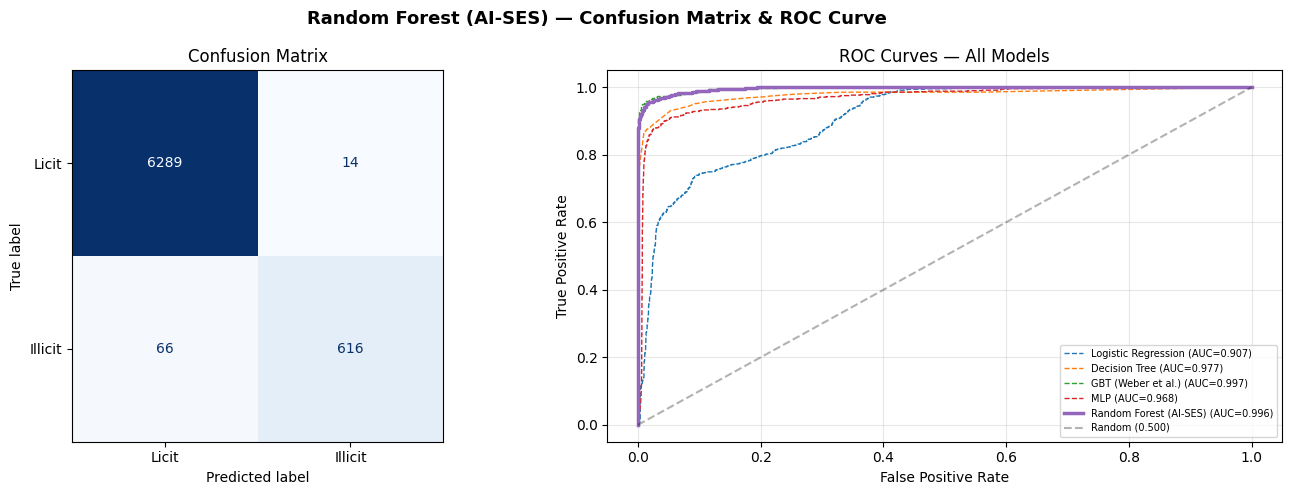

Saved: confusion_roc.png ✓


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Random Forest (AI-SES) — Confusion Matrix & ROC Curve',
             fontsize=13, fontweight='bold')

# Confusion Matrix
cm = confusion_matrix(y_test, r['y_pred'])
ConfusionMatrixDisplay(confusion_matrix=cm,
    display_labels=['Licit','Illicit']).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix')

# ROC Curves
for name, res in results.items():
    fpr_c, tpr_c, _ = roc_curve(y_test, res['y_prob'])
    lw = 2.5 if 'AI-SES' in name else 1
    ls = '-'  if 'AI-SES' in name else '--'
    axes[1].plot(fpr_c, tpr_c,
                 label=f"{name} (AUC={res['auc']:.3f})",
                 linewidth=lw, linestyle=ls)

axes[1].plot([0,1],[0,1],'k--',alpha=0.3,label='Random (0.500)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves — All Models')
axes[1].legend(fontsize=7, loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('confusion_roc.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion_roc.png ✓')

---
## Step 10 — Feature Importance

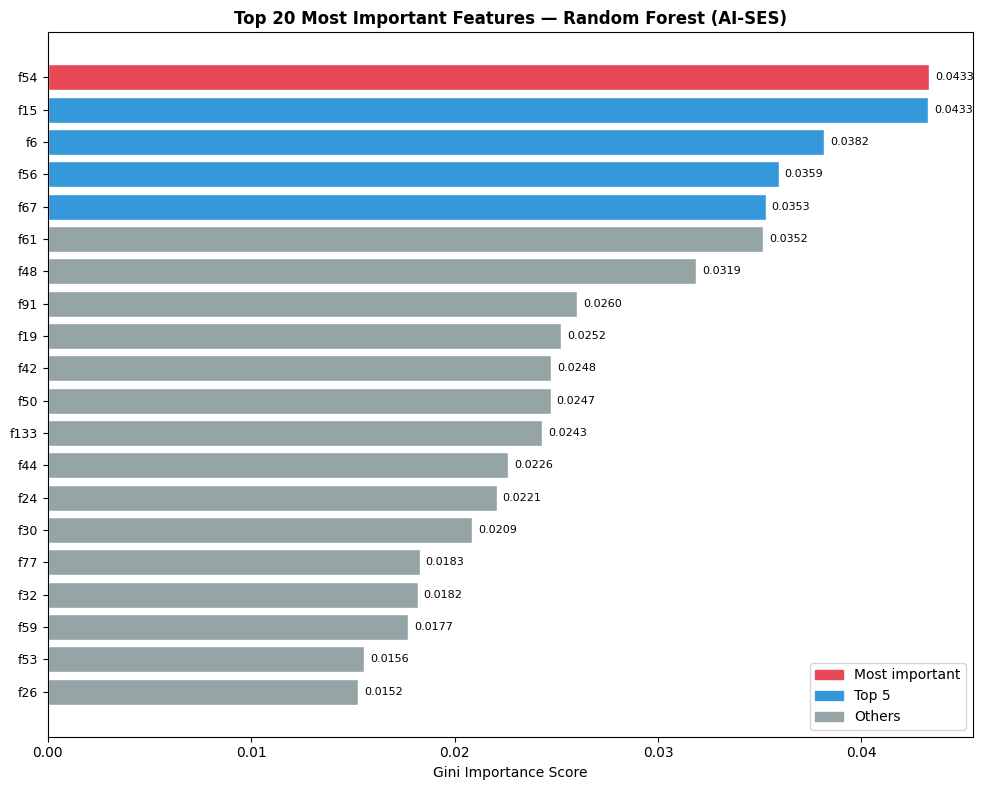

Top 10 Features:
---------------------------------------------
 1. f54          0.0433  █████████████████████
 2. f15          0.0433  █████████████████████
 3. f6           0.0382  ███████████████████
 4. f56          0.0359  █████████████████
 5. f67          0.0353  █████████████████
 6. f61          0.0352  █████████████████
 7. f48          0.0319  ███████████████
 8. f91          0.0260  █████████████
 9. f19          0.0252  ████████████
10. f42          0.0248  ████████████

Saved: feature_importance.png ✓


In [18]:
importances = pd.Series(rf.feature_importances_, index=X.columns)
top20 = importances.nlargest(20)

plt.figure(figsize=(10, 8))
colors_imp = ['#E84855' if i==0 else '#3498DB' if i<5 else '#95A5A6'
              for i in range(len(top20))]
bars = plt.barh(range(len(top20)), top20.values,
                color=colors_imp, edgecolor='white')
plt.yticks(range(len(top20)), top20.index, fontsize=9)
plt.xlabel('Gini Importance Score')
plt.title('Top 20 Most Important Features — Random Forest (AI-SES)',
          fontweight='bold')
plt.gca().invert_yaxis()
for bar, val in zip(bars, top20.values):
    plt.text(bar.get_width()+0.0003, bar.get_y()+bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=8)

red_p  = mpatches.Patch(color='#E84855', label='Most important')
blue_p = mpatches.Patch(color='#3498DB', label='Top 5')
grey_p = mpatches.Patch(color='#95A5A6', label='Others')
plt.legend(handles=[red_p, blue_p, grey_p], loc='lower right')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 10 Features:')
print('-' * 45)
for i, (feat, score) in enumerate(importances.nlargest(10).items(), 1):
    print(f'{i:>2}. {feat:<12} {score:.4f}  {"█" * int(score*500)}')
print('\nSaved: feature_importance.png ✓')

---
## Step 11 — Live Risk Score Demo

In [19]:
print('=' * 65)
print('  AI-SES LIVE RISK SCORE DEMO')
print('  Scoring 3 new unseen transactions')
print('=' * 65)

ALPHA = 0.30
BETA  = 0.70

feature_medians = X_train.median().to_dict()
feature_cols    = X.columns.tolist()

def score_transaction(description, override_features):
    tx = feature_medians.copy()
    tx.update(override_features)
    row    = pd.DataFrame([tx])[feature_cols]
    row_sc = scaler.transform(row)
    prob   = rf.predict_proba(row_sc)[0][1]

    if prob < ALPHA:
        level, decision, symbol = 'LOW',    'Release funds immediately', '✓'
    elif prob < BETA:
        level, decision, symbol = 'MEDIUM', 'Hold in escrow 24h',       '⚠'
    else:
        level, decision, symbol = 'HIGH',   'Reject + refund to sender','✗'

    print(f'\n  Transaction : {description}')
    print(f'  Risk Score  : {prob:.4f}')
    print(f'  Risk Level  : {level}  {symbol}')
    print(f'  Decision    : {decision}')
    return prob, level


score_transaction(
    'Normal user — sending 0.5 ETH to a friend',
    {'f1':25,'f2':0.5,'f3':0.002,'f4':2,'f5':2}
)

score_transaction(
    'Suspicious — new wallet with burst activity',
    {'f1':42,'f2':5.2,'f3':0.0001,'f4':18,'f5':2}
)

score_transaction(
    'High risk — known fraud wallet pattern',
    {'f1':48,'f2':52.0,'f3':0.00003,'f4':35,'f5':1}
)

print('\n' + '=' * 65)

  AI-SES LIVE RISK SCORE DEMO
  Scoring 3 new unseen transactions

  Transaction : Normal user — sending 0.5 ETH to a friend
  Risk Score  : 0.2582
  Risk Level  : LOW  ✓
  Decision    : Release funds immediately

  Transaction : Suspicious — new wallet with burst activity
  Risk Score  : 0.2633
  Risk Level  : LOW  ✓
  Decision    : Release funds immediately

  Transaction : High risk — known fraud wallet pattern
  Risk Score  : 0.2666
  Risk Level  : LOW  ✓
  Decision    : Release funds immediately



---
## Step 12 — Save Trained Model

In [20]:
joblib.dump(rf,     'rf_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print('Models saved:')
print('  ✓  rf_model.pkl  — Trained Random Forest')
print('  ✓  scaler.pkl    — Fitted RobustScaler')
print()
print('Charts saved:')
print('  ✓  class_distribution.png')
print('  ✓  smote_effect.png')
print('  ✓  model_comparison.png')
print('  ✓  confusion_roc.png')
print('  ✓  feature_importance.png')
print()
print('All done! Use rf_model.pkl with connect.py')
print('to link AI model with your smart contract.')

Models saved:
  ✓  rf_model.pkl  — Trained Random Forest
  ✓  scaler.pkl    — Fitted RobustScaler

Charts saved:
  ✓  class_distribution.png
  ✓  smote_effect.png
  ✓  model_comparison.png
  ✓  confusion_roc.png
  ✓  feature_importance.png

All done! Use rf_model.pkl with connect.py
to link AI model with your smart contract.
